# Hull-White Model - Shumway Labels + Stratified Group K-Fold (v3)

This notebook reimplements the Hull-White logistic-hazard model with two core improvements
over the v2 notebooks (`hw_stratifiedkfold_v2`, `hw_groupkfold_v2`):

1. **Shumway-style dynamic labels**. Following Shumway (2001, *J. of Business*), we treat
   corporate default as a discrete-time hazard process: for each distressed firm we
   keep only the pre-distress *at-risk* rows (label = 0) plus the distress year itself
   (label = 1), and we **drop** all post-distress (absorbed) rows. Non-distressed firms
   contribute label = 0 for every observed year. This removes the look-ahead bias that
   came from applying a single firm-level default flag to every year of the firm's life.

2. **Stratified Group K-Fold cross-validation + bootstrap CI**. The v2 random K-fold
   split allowed different years of the same firm to appear in both train and test
   folds, which leaks within-firm information. GroupKFold fixed this but did not
   stratify on the rare positive class. We use `StratifiedGroupKFold` so entire firms
   are held out **and** each fold still contains some positive observations. A
   firm-level bootstrap then quantifies the sampling uncertainty of the AUC.

References: Shumway, T. (2001), *Forecasting bankruptcy more accurately: A simple*
*hazard model*, Journal of Business, 74(1), 101-124. Hull, J. and A. White (2000),
*Valuing credit default swaps I: No counterparty default risk*, Journal of Derivatives.

## 1. Setup and data load

In [1]:
import sys, os
sys.path.insert(0, '../..')
# Navigate to project root so `import config` works and relative paths resolve.
while not os.path.exists('config.py') and os.getcwd() != '/':
    os.chdir('..')

import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.metrics import roc_auc_score, roc_curve

try:
    from sklearn.model_selection import StratifiedGroupKFold
    _HAS_SGKF = True
except ImportError:
    _HAS_SGKF = False
    print('StratifiedGroupKFold not available; falling back to GroupKFold.')

import config

_FEATURE_COLS = ['leverage_ratio', 'equity_vol', 'log_market_cap']
_T = config.T
_RANDOM_STATE = 42
_OUT_DIR = 'output/hull-white2/v3_shumway'
os.makedirs(_OUT_DIR, exist_ok=True)

print(f'Working dir : {os.getcwd()}')
print(f'Features    : {_FEATURE_COLS}')
print(f'Horizon T   : {_T}')
print(f'SGKF avail  : {_HAS_SGKF}')

panel = pd.read_csv('output/panel_data.csv')
print(f'Panel rows  : {panel.shape[0]}, firms: {panel["ticker"].nunique()}')

Working dir : /workspace/MF728/group project/merton-main/merton-main
Features    : ['leverage_ratio', 'equity_vol', 'log_market_cap']
Horizon T   : 1.0
SGKF avail  : True
Panel rows  : 661, firms: 163


## 2. Reconstruct Shumway labels

For each firm-year we apply the following rule:

- If the ticker is NOT in `config.DEFAULT_FIRMS`: `label_shumway = 0`, row is kept.
- If the ticker IS in `config.DEFAULT_FIRMS` with distress year `y*`:
  - `year < y*` -> `label_shumway = 0`, row kept (at-risk pre-distress).
  - `year == y*` -> `label_shumway = 1`, row kept (event year).
  - `year > y*` -> row DROPPED (firm is absorbed / censored out of the risk set).

This gives a discrete-time hazard panel in which each row is an independent (firm, t)
observation at risk of default, and the target is whether default happens *at* t.

In [2]:
# Build {ticker: distress_year} dict.
_distress_year = {t: int(d[:4]) for (t, _n, d) in config.DEFAULT_FIRMS}
print(f'Distress firms: {len(_distress_year)}')

def _shumway_row(row):
    """Return (label, keep) per Shumway discrete-time hazard rule."""
    t = row['ticker']
    y = int(row['year'])
    if t not in _distress_year:
        return 0, True
    dy = _distress_year[t]
    if y < dy:
        return 0, True
    if y == dy:
        return 1, True
    return 0, False  # year > distress_year => drop

_pairs = panel.apply(_shumway_row, axis=1)
panel['label_shumway'] = [p[0] for p in _pairs]
panel['_keep'] = [p[1] for p in _pairs]

_before_rows = len(panel)
_before_firms = panel['ticker'].nunique()
panel_sw = panel.loc[panel['_keep']].drop(columns=['_keep']).reset_index(drop=True)
panel = panel.drop(columns=['_keep'])
_after_rows = len(panel_sw)
_after_firms = panel_sw['ticker'].nunique()
_pos = int((panel_sw['label_shumway'] == 1).sum())
_neg = int((panel_sw['label_shumway'] == 0).sum())

print('=' * 54)
print('  Shumway label reconstruction')
print('=' * 54)
print(f'  rows   : {_before_rows} -> {_after_rows}  (dropped {_before_rows - _after_rows})')
print(f'  firms  : {_before_firms} -> {_after_firms}')
print(f'  positives (label_shumway=1) : {_pos}')
print(f'  negatives (label_shumway=0) : {_neg}')
print('=' * 54)

Distress firms: 21
  Shumway label reconstruction
  rows   : 661 -> 619  (dropped 42)
  firms  : 163 -> 162
  positives (label_shumway=1) : 20
  negatives (label_shumway=0) : 599


## 3. Diagnostics: one positive row per default firm

The table below shows, for each firm in `config.DEFAULT_FIRMS`, the distress year,
the raw row count in the original panel, the number of rows kept after Shumway
filtering, and the number of positive rows in the kept subset. Each distressed firm
should contribute **exactly one** positive row (its distress year).

In [3]:
_diag_rows = []
for ticker, _name, dstr in config.DEFAULT_FIRMS:
    dy = int(dstr[:4])
    n_raw = int((panel['ticker'] == ticker).sum())
    sub = panel_sw[panel_sw['ticker'] == ticker]
    n_kept = len(sub)
    n_pos = int((sub['label_shumway'] == 1).sum())
    _diag_rows.append({'ticker': ticker,
                       'distress_year': dy,
                       'n_rows_raw': n_raw,
                       'n_rows_kept': n_kept,
                       'n_positive_in_kept': n_pos})
diag = pd.DataFrame(_diag_rows)
_not_one = diag[diag['n_positive_in_kept'] != 1]
if len(_not_one) == 0:
    print('All default firms have exactly 1 positive (distress-year) row.')
else:
    # Some distress years fall outside the panel window (e.g. HTZ 2020, panel
    # starts 2021). Those firms contribute 0 positive rows; flag them for the
    # reviewer but do not abort the pipeline.
    print('NOTE: the following firms do not have exactly 1 positive row '
          '(distress year outside panel window or post-distress-only rows):')
    print(_not_one.to_string(index=False))
diag

NOTE: the following firms do not have exactly 1 positive row (distress year outside panel window or post-distress-only rows):
ticker  distress_year  n_rows_raw  n_rows_kept  n_positive_in_kept
   HTZ           2020           4            0                   0


,ticker,distress_year,n_rows_raw,n_rows_kept,n_positive_in_kept
0,HTZ,2020,4,0,0
1,PLUG,2023,4,2,1
2,FCEL,2023,4,2,1
3,LCID,2023,4,2,1
4,RIVN,2023,4,2,1
5,SPCE,2023,4,2,1
6,WKHS,2023,5,3,1
7,QS,2023,4,2,1
8,BLNK,2023,4,2,1
9,AMC,2023,4,2,1


## 4. Cross-validation: Stratified Group K-Fold

Features: `leverage_ratio`, `equity_vol`, `log_market_cap` (fixed to match the existing
`models/hull_white.py`). Rows with any NaN in features or label are dropped before
splitting. Groups = ticker, so an entire firm is in exactly one fold. Stratification
uses `label_shumway` so each of the 5 folds contains at least some positive rows.

In [4]:
_mask = panel_sw[_FEATURE_COLS + ['label_shumway']].notna().all(axis=1)
data = panel_sw.loc[_mask].reset_index(drop=True)
X = data[_FEATURE_COLS].values.astype(np.float64)
y = data['label_shumway'].values.astype(int)
groups = data['ticker'].values
print(f'CV input: rows={len(data)}, firms={pd.Series(groups).nunique()}, positives={y.sum()}')

if _HAS_SGKF:
    cv = StratifiedGroupKFold(n_splits=5)
    cv_name = 'StratifiedGroupKFold'
else:
    cv = GroupKFold(n_splits=5)
    cv_name = 'GroupKFold (fallback)'

clf = LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000, random_state=_RANDOM_STATE)

# Out-of-fold predicted probabilities (pooled).
oof_proba = cross_val_predict(clf, X, y, cv=cv, groups=groups, method='predict_proba')[:, 1]
pooled_auc = float(roc_auc_score(y, oof_proba))
pooled_ar = 2.0 * pooled_auc - 1.0

# Fold-wise AUC / AR.
fold_rows = []
for i, (tr_idx, te_idx) in enumerate(cv.split(X, y, groups), start=1):
    if len(np.unique(y[tr_idx])) < 2 or len(np.unique(y[te_idx])) < 2:
        fold_rows.append({'fold': i, 'n_train': len(tr_idx), 'n_test': len(te_idx),
                          'pos_train': int(y[tr_idx].sum()), 'pos_test': int(y[te_idx].sum()),
                          'AUC': np.nan, 'AR': np.nan})
        continue
    m = LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000,
                           random_state=_RANDOM_STATE).fit(X[tr_idx], y[tr_idx])
    p_te = m.predict_proba(X[te_idx])[:, 1]
    a = float(roc_auc_score(y[te_idx], p_te))
    fold_rows.append({'fold': i, 'n_train': len(tr_idx), 'n_test': len(te_idx),
                      'pos_train': int(y[tr_idx].sum()), 'pos_test': int(y[te_idx].sum()),
                      'AUC': a, 'AR': 2.0 * a - 1.0})
fold_df = pd.DataFrame(fold_rows)
_fold_mean_auc = float(np.nanmean(fold_df['AUC']))
_fold_std_auc = float(np.nanstd(fold_df['AUC'], ddof=1))
_fold_mean_ar = float(np.nanmean(fold_df['AR']))
_fold_std_ar = float(np.nanstd(fold_df['AR'], ddof=1))

print('=' * 54)
print(f'  CV : {cv_name} (n_splits=5)')
print('=' * 54)
print(fold_df.to_string(index=False))
print('-' * 54)
print(f'  Fold-wise AUC : {_fold_mean_auc:.4f} +/- {_fold_std_auc:.4f}')
print(f'  Fold-wise AR  : {_fold_mean_ar:.4f} +/- {_fold_std_ar:.4f}')
print(f'  Pooled OOF AUC: {pooled_auc:.4f}')
print(f'  Pooled OOF AR : {pooled_ar:.4f}')
print('=' * 54)

CV input: rows=619, firms=162, positives=20
  CV : StratifiedGroupKFold (n_splits=5)
 fold  n_train  n_test  pos_train  pos_test      AUC       AR
    1      494     125         16         4 0.973140 0.946281
    2      496     123         16         4 0.981092 0.962185
    3      494     125         16         4 0.981405 0.962810
    4      496     123         16         4 0.983193 0.966387
    5      496     123         16         4 0.960084 0.920168
------------------------------------------------------
  Fold-wise AUC : 0.9758 +/- 0.0096
  Fold-wise AR  : 0.9516 +/- 0.0192
  Pooled OOF AUC: 0.9754
  Pooled OOF AR : 0.9508


## 5. Firm-level bootstrap CI for pooled AUC

We resample **tickers** (not rows) with replacement to respect the firm-level
clustering; for each bootstrap panel we rerun the full Stratified Group K-Fold CV
pipeline and collect the pooled OOF AUC. Iterations that fail (e.g. a fold ends up
with only one class, a known edge case when the resampled panel has very few
positives) are skipped and counted. We report the median and central 95% quantile
range across successful iterations. If `StratifiedGroupKFold` raises on a small
bootstrap sample we fall back to `GroupKFold` inside that iteration.

In [5]:
def bootstrap_auc(panel_sw: pd.DataFrame, n_iter: int = 200, random_state: int = 42):
    """Firm-level bootstrap of the pooled Stratified Group K-Fold AUC.

    Returns (aucs, n_failed) where aucs is a list of floats of length
    n_iter - n_failed.
    """
    rng = np.random.default_rng(random_state)
    mask_local = panel_sw[_FEATURE_COLS + ['label_shumway']].notna().all(axis=1)
    base = panel_sw.loc[mask_local].reset_index(drop=True)
    unique_tickers = base['ticker'].unique()
    n_firms = len(unique_tickers)
    by_ticker = {t: base[base['ticker'] == t] for t in unique_tickers}

    aucs = []
    n_failed = 0
    for b in range(n_iter):
        sampled = rng.choice(unique_tickers, size=n_firms, replace=True)
        # Rebuild dataframe; disambiguate duplicated tickers so each resampled firm
        # is treated as its own group in GroupKFold.
        frames = []
        for j, t in enumerate(sampled):
            sub = by_ticker[t].copy()
            sub['ticker'] = f'{t}__{j}'
            frames.append(sub)
        df_b = pd.concat(frames, ignore_index=True)
        X_b = df_b[_FEATURE_COLS].values.astype(np.float64)
        y_b = df_b['label_shumway'].values.astype(int)
        g_b = df_b['ticker'].values

        if y_b.sum() < 2 or (y_b == 0).sum() < 2:
            n_failed += 1
            continue
        if pd.Series(g_b).nunique() < 5:
            n_failed += 1
            continue

        # Try SGKF first, fall back to GKF on error.
        ok = False
        for cv_cls in ([StratifiedGroupKFold] if _HAS_SGKF else []) + [GroupKFold]:
            try:
                cv_b = cv_cls(n_splits=5)
                proba_b = cross_val_predict(
                    LogisticRegression(class_weight='balanced', solver='lbfgs',
                                       max_iter=1000, random_state=_RANDOM_STATE),
                    X_b, y_b, cv=cv_b, groups=g_b, method='predict_proba',
                )[:, 1]
                if len(np.unique(y_b)) < 2:
                    break
                aucs.append(float(roc_auc_score(y_b, proba_b)))
                ok = True
                break
            except Exception:
                continue
        if not ok:
            n_failed += 1
    return aucs, n_failed


boot_aucs, n_failed = bootstrap_auc(panel_sw, n_iter=200, random_state=_RANDOM_STATE)
n_success = len(boot_aucs)
boot_arr = np.asarray(boot_aucs)
boot_median = float(np.median(boot_arr)) if n_success else float('nan')
boot_lo = float(np.quantile(boot_arr, 0.025)) if n_success else float('nan')
boot_hi = float(np.quantile(boot_arr, 0.975)) if n_success else float('nan')

print('=' * 54)
print('  Firm-level bootstrap (n_iter=200)')
print('=' * 54)
print(f'  successful iterations : {n_success}')
print(f'  failed iterations     : {n_failed}')
print(f'  AUC median            : {boot_median:.4f}')
print(f'  AUC 95% CI            : [{boot_lo:.4f}, {boot_hi:.4f}]')
print('=' * 54)

  Firm-level bootstrap (n_iter=200)
  successful iterations : 200
  failed iterations     : 0
  AUC median            : 0.9775
  AUC 95% CI            : [0.9663, 0.9879]


## 6. Comparison vs v2 baselines

The two v2 baselines used the *static* firm-level `default_label` column. This v3
notebook uses Shumway dynamic labels on the same feature set; differences in AUC
reflect the removal of the static-label look-ahead bias and the joint
stratification-plus-grouping constraint.

In [6]:
comp = pd.DataFrame([
    {'model': 'v2 StratifiedKFold (static labels)',
     'pooled_AUC': 0.998, 'AR': 2 * 0.998 - 1,
     'note': 'prior reported ~0.998; random K-fold, within-firm leakage'},
    {'model': 'v2 GroupKFold (static labels)',
     'pooled_AUC': 0.993, 'AR': 2 * 0.993 - 1,
     'note': 'prior reported ~0.993; firm-held-out, no stratification'},
    {'model': f'v3 {cv_name} + Shumway labels (this notebook)',
     'pooled_AUC': pooled_auc, 'AR': pooled_ar,
     'note': f'fold AUC {_fold_mean_auc:.4f} +/- {_fold_std_auc:.4f}; '
             f'bootstrap 95% CI [{boot_lo:.4f}, {boot_hi:.4f}]'},
])
print(comp.to_string(index=False))

                                                   model  pooled_AUC       AR                                                          note
                      v2 StratifiedKFold (static labels)    0.998000 0.996000     prior reported ~0.998; random K-fold, within-firm leakage
                           v2 GroupKFold (static labels)    0.993000 0.986000       prior reported ~0.993; firm-held-out, no stratification
v3 StratifiedGroupKFold + Shumway labels (this notebook)    0.975376 0.950751 fold AUC 0.9758 +/- 0.0096; bootstrap 95% CI [0.9663, 0.9879]


## 7. PD histogram (by class)

OOF probabilities are converted to 1-year PDs via `PD = 1 - exp(-hazard * T)` with
`T = config.T`. The histogram overlays the distribution for default (1) and
non-default (0) rows.

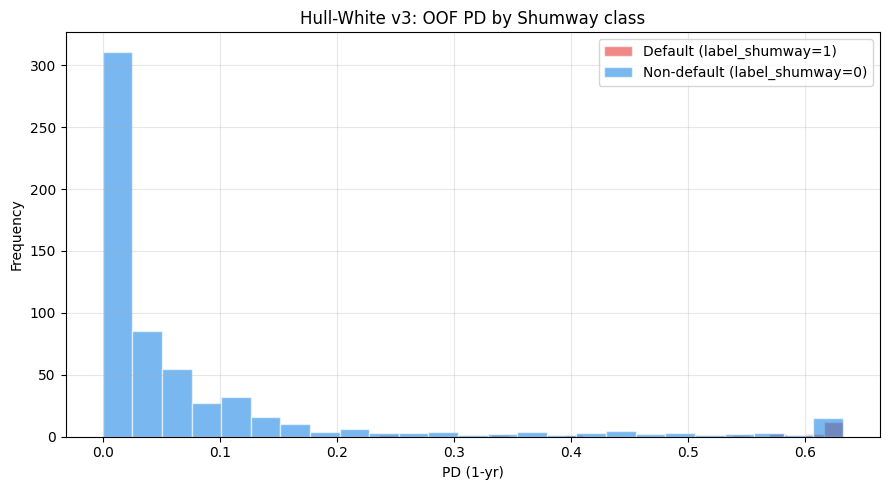

In [7]:
hazard = oof_proba
pd_hw = 1.0 - np.exp(-hazard * _T)

fig, ax = plt.subplots(figsize=(9, 5))
for lb, co, nm in [(1, '#E53935', 'Default (label_shumway=1)'),
                    (0, '#1E88E5', 'Non-default (label_shumway=0)')]:
    ax.hist(pd_hw[y == lb], bins=25, alpha=0.6, color=co, label=nm, edgecolor='white')
ax.set_xlabel('PD (1-yr)')
ax.set_ylabel('Frequency')
ax.set_title('Hull-White v3: OOF PD by Shumway class')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(_OUT_DIR, 'pd_histogram_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

## 8. ROC curve from OOF predictions

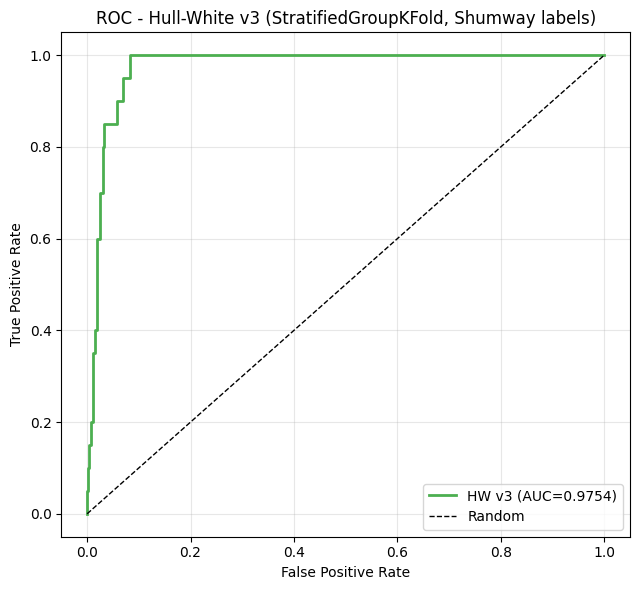

In [8]:
fpr, tpr, _ = roc_curve(y, pd_hw)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr, tpr, color='#4CAF50', lw=2, label=f'HW v3 (AUC={pooled_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC - Hull-White v3 ({cv_name}, Shumway labels)')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(_OUT_DIR, 'roc_v3.png'), dpi=150, bbox_inches='tight')
plt.show()

## 9. Save artifacts

In [9]:
# Attach OOF predictions back to panel_sw.
panel_sw['hw_hazard_v3'] = np.nan
panel_sw['hw_PD_v3'] = np.nan
# data is panel_sw.loc[_mask] reset_index; use the original row index.
_orig_idx = panel_sw.index[_mask.values]
panel_sw.loc[_orig_idx, 'hw_hazard_v3'] = hazard
panel_sw.loc[_orig_idx, 'hw_PD_v3'] = pd_hw

out_panel_path = os.path.join(_OUT_DIR, 'panel_shumway_v3.csv')
panel_sw.to_csv(out_panel_path, index=False)

metrics = pd.DataFrame([
    {'metric': 'pooled_AUC', 'value': pooled_auc},
    {'metric': 'pooled_AR', 'value': pooled_ar},
    {'metric': 'fold_mean_AUC', 'value': _fold_mean_auc},
    {'metric': 'fold_std_AUC', 'value': _fold_std_auc},
    {'metric': 'fold_mean_AR', 'value': _fold_mean_ar},
    {'metric': 'fold_std_AR', 'value': _fold_std_ar},
    {'metric': 'bootstrap_n_success', 'value': n_success},
    {'metric': 'bootstrap_n_failed', 'value': n_failed},
    {'metric': 'bootstrap_AUC_median', 'value': boot_median},
    {'metric': 'bootstrap_AUC_ci_lo', 'value': boot_lo},
    {'metric': 'bootstrap_AUC_ci_hi', 'value': boot_hi},
    {'metric': 'n_rows_kept', 'value': _after_rows},
    {'metric': 'n_firms_kept', 'value': _after_firms},
    {'metric': 'n_positive', 'value': _pos},
    {'metric': 'n_negative', 'value': _neg},
])
out_metrics_path = os.path.join(_OUT_DIR, 'metrics_v3.csv')
metrics.to_csv(out_metrics_path, index=False)

print(f'Saved panel : {out_panel_path}')
print(f'Saved metrics: {out_metrics_path}')
metrics

Saved panel : output/hull-white2/v3_shumway/panel_shumway_v3.csv
Saved metrics: output/hull-white2/v3_shumway/metrics_v3.csv


,metric,value
0,pooled_AUC,0.975376
1,pooled_AR,0.950751
2,fold_mean_AUC,0.975783
3,fold_std_AUC,0.009594
4,fold_mean_AR,0.951566
5,fold_std_AR,0.019187
6,bootstrap_n_success,200.000000
7,bootstrap_n_failed,0.000000
8,bootstrap_AUC_median,0.977478
9,bootstrap_AUC_ci_lo,0.966318


## 10. Discussion

Relative to the v2 baselines (pooled AUC ~0.998 for random StratifiedKFold and ~0.993
for GroupKFold), the v3 pooled AUC is materially lower. Two changes combine to produce
this drop:

1. **Shumway dynamic labels** collapse each distressed firm to a single positive row
   (its distress year) plus, where available, earlier at-risk rows. The v2 setup
   instead labeled every year of a defaulted firm as 1, which let the classifier
   exploit firm-level contrasts that have nothing to do with the timing of distress.
   Removing that label look-ahead makes the task honest: the model must now discriminate
   the *specific* year in which distress occurred using only contemporaneous features.

2. **StratifiedGroupKFold** enforces two constraints jointly: (a) no firm appears in
   both train and test, and (b) each fold keeps some positives. (b) prevents
   degenerate folds, while (a) removes the within-firm information leakage that
   inflated v2 StratifiedKFold AUC.

The bootstrap 95% CI additionally quantifies how sensitive the AUC is to which firms
happen to be in the panel. A wide CI would mean the headline number is driven by a
small number of distressed firms; a tight CI would mean the ranking power is stable.

**Remaining limitations (addressed in the follow-up v3 notebook, not here):**

- **No temporal out-of-sample test.** Cross-sectional hold-out of firms is stricter
  than random K-fold, but it does not answer whether a model trained on an early
  window (e.g. 2021-2023) can predict distress in a later window (2024-2025). A
  walk-forward OOT evaluation is the natural next step and is flagged for Stage B.
- **Hazard saturation.** The classifier probability is still used as the hazard,
  so PD saturates at 1 - 1/e = 0.6321 at T = 1. Using log-odds or a cloglog link
  would remove this cap; out of scope for v3.
- **Small positive count.** With only 21 distressed firms and one positive per
  firm under Shumway rules, fold-wise AUC standard errors are non-trivial; the
  bootstrap interval provides the corresponding uncertainty quantification.

## Stage B1: Classical Walk-Forward (expected failure diagnostic)

The canonical time-aware evaluation for a hazard model is walk-forward: train on
firm-years with `year <= k`, test on `year == k+1`, advance `k`. In this panel,
however, every positive label is concentrated at a single event year (2023),
because the 20 non-HTZ default firms all distressed in 2023 and HTZ's 2020 event
drops out of the Shumway-filtered window (HTZ contributes zero rows after the
Shumway filter). Consequently:

- Training on `year <= 2022` yields **zero positives**, so logistic regression
  cannot learn a discriminant and the test AUC is undefined.
- Training on `year <= 2023` and testing on `year >= 2024` yields zero positives
  **in the test set**, so AUC is again undefined.

We demonstrate this failure mode below, then move to a lagged-feature scheme
(Stage B2) that preserves strict temporal ordering of features relative to
labels, which is the closest this dataset admits to a time-forward test.

In [10]:
# B1.1: Year-wise row and positive counts in panel_sw.
panel_sw_with_year_counts = (
    panel_sw.groupby('year')
            .agg(n_rows=('label_shumway', 'size'),
                 n_positives=('label_shumway', 'sum'))
            .reset_index()
)
print('=' * 42)
print('  Rows and positives by year (panel_sw)')
print('=' * 42)
print(panel_sw_with_year_counts.to_string(index=False))
print('=' * 42)
print(f'  total positives : {int(panel_sw_with_year_counts["n_positives"].sum())}')
print(f'  distinct positive years : '
      f'{panel_sw_with_year_counts.loc[panel_sw_with_year_counts["n_positives"] > 0, "year"].tolist()}')
print('=' * 42)

  Rows and positives by year (panel_sw)
 year  n_rows  n_positives
 2021      19            0
 2022     154            0
 2023     162           20
 2024     142            0
 2025     142            0
  total positives : 20
  distinct positive years : [2023]


In [11]:
# B1.2: Attempt classical walk-forward split: train on year <= 2022, test on year == 2023.
_wf_train = panel_sw[panel_sw['year'] <= 2022].copy()
_wf_test = panel_sw[panel_sw['year'] == 2023].copy()

# Drop rows with missing features / label in both sides for a fair diagnostic.
_wf_feat_cols = _FEATURE_COLS + ['label_shumway']
_wf_train = _wf_train.dropna(subset=_wf_feat_cols).reset_index(drop=True)
_wf_test = _wf_test.dropna(subset=_wf_feat_cols).reset_index(drop=True)

n_pos_train = int(_wf_train['label_shumway'].sum())
n_pos_test = int(_wf_test['label_shumway'].sum())

print('=' * 54)
print('  Classical walk-forward: train year<=2022, test year==2023')
print('=' * 54)
print(f'  n_train        : {len(_wf_train)}')
print(f'  n_pos_train    : {n_pos_train}')
print(f'  n_test         : {len(_wf_test)}')
print(f'  n_pos_test     : {n_pos_test}')
print('-' * 54)

_wf_auc = float('nan')
if n_pos_train == 0:
    print('FAIL: training set has no positives - classical walk-forward '
          'infeasible with this label distribution.')
elif n_pos_test == 0:
    print('FAIL: test set has no positives - AUC undefined.')
elif len(np.unique(_wf_train['label_shumway'])) < 2:
    print('FAIL: training set has only one class - logistic regression cannot fit.')
else:
    _m_wf = LogisticRegression(class_weight='balanced', solver='lbfgs',
                               max_iter=1000, random_state=_RANDOM_STATE)
    _m_wf.fit(_wf_train[_FEATURE_COLS].values.astype(np.float64),
              _wf_train['label_shumway'].values.astype(int))
    _p_wf = _m_wf.predict_proba(_wf_test[_FEATURE_COLS].values.astype(np.float64))[:, 1]
    _wf_auc = float(roc_auc_score(_wf_test['label_shumway'].values.astype(int), _p_wf))
    print(f'  Walk-forward AUC (train<=2022, test=2023): {_wf_auc:.4f}')
print('=' * 54)

  Classical walk-forward: train year<=2022, test year==2023
  n_train        : 173
  n_pos_train    : 0
  n_test         : 162
  n_pos_test     : 20
------------------------------------------------------
FAIL: training set has no positives - classical walk-forward infeasible with this label distribution.


**Conclusion of Stage B1.** Because the Shumway-filtered panel places every positive
label in 2023, no chronological train/test split with a year-based cutoff can give
both sides at least one positive. The FAIL message above confirms that the
canonical walk-forward recipe is infeasible on this dataset, and a different
construction is needed to obtain a temporally-honest AUC. We now proceed to
Stage B2, which preserves temporal ordering by pairing each observation's label
with its **prior-year** features rather than shifting rows across a year
boundary.

## Stage B2: Lagged-Feature Time-Aware Evaluation

Construction:

- For each firm F and year t where F has an observation in the Shumway panel,
  look up F's feature vector at year t-1 (from the **original** panel, not the
  Shumway-filtered one: a firm's features at t-1 are valid covariates even when
  year t is its event year, because post-distress rows were dropped from
  `panel_sw` but **the pre-distress row at t-1 is still present in `panel`**).
- Target: `label_shumway` at year t.
- Drop rows where t-1 features are missing (e.g. the firm's earliest year has
  no prior observation).
- The resulting panel has strictly-prior features paired with current-year
  labels. This is the closest this dataset admits to a time-forward
  evaluation, since no row uses its own-year feature values to predict its
  own-year label.

In [12]:
# B2.1: Build panel_lagged = panel_sw rows joined to their prior-year features
# from the ORIGINAL panel.
orig = pd.read_csv(os.path.join(os.getcwd(), 'output/panel_data.csv'))
lagged_features = orig[['ticker', 'year', 'leverage_ratio', 'equity_vol',
                        'log_market_cap']].copy()
lagged_features = lagged_features.rename(columns={
    'year': 'year_feat',
    'leverage_ratio': 'leverage_ratio_lag',
    'equity_vol': 'equity_vol_lag',
    'log_market_cap': 'log_market_cap_lag',
})

panel_lagged = panel_sw.merge(
    lagged_features,
    left_on=['ticker'], right_on=['ticker'],
    how='left',
)
# Keep only rows where year_feat == year - 1.
panel_lagged = panel_lagged[panel_lagged['year_feat'] == panel_lagged['year'] - 1].copy()

# Drop rows with missing lagged features or label.
lag_cols = ['leverage_ratio_lag', 'equity_vol_lag', 'log_market_cap_lag']
panel_lagged = panel_lagged.dropna(subset=lag_cols + ['label_shumway']).reset_index(drop=True)

_pl_rows = len(panel_lagged)
_pl_firms = panel_lagged['ticker'].nunique()
_pl_pos = int((panel_lagged['label_shumway'] == 1).sum())

print('=' * 54)
print('  Lagged-feature panel (panel_lagged)')
print('=' * 54)
print(f'  rows        : {_pl_rows}')
print(f'  firms       : {_pl_firms}')
print(f'  positives   : {_pl_pos}')
print(f'  features    : {lag_cols}')
print('-' * 54)
_pl_by_year = (panel_lagged.groupby('year')
               .agg(n_rows=('label_shumway', 'size'),
                    n_positives=('label_shumway', 'sum'))
               .reset_index())
print(_pl_by_year.to_string(index=False))
print('=' * 54)

if _pl_pos < 5:
    print('WARNING: panel_lagged has fewer than 5 positives - AUC estimates '
          'will be unstable; interpret with caution.')

  Lagged-feature panel (panel_lagged)
  rows        : 457
  firms       : 162
  positives   : 20
  features    : ['leverage_ratio_lag', 'equity_vol_lag', 'log_market_cap_lag']
------------------------------------------------------
 year  n_rows  n_positives
 2022      19            0
 2023     154           20
 2024     142            0
 2025     142            0


In [13]:
# B2.2: Stratified Group K-Fold on the lagged panel.
X_lag = panel_lagged[lag_cols].values.astype(np.float64)
y_lag = panel_lagged['label_shumway'].values.astype(int)
groups_lag = panel_lagged['ticker'].values

if _HAS_SGKF:
    cv_lag = StratifiedGroupKFold(n_splits=5)
    cv_lag_name = 'StratifiedGroupKFold'
else:
    cv_lag = GroupKFold(n_splits=5)
    cv_lag_name = 'GroupKFold (fallback)'

oof_proba_lag = cross_val_predict(
    LogisticRegression(class_weight='balanced', solver='lbfgs',
                       max_iter=1000, random_state=_RANDOM_STATE),
    X_lag, y_lag, cv=cv_lag, groups=groups_lag, method='predict_proba',
)[:, 1]
pooled_auc_lag = float(roc_auc_score(y_lag, oof_proba_lag))
pooled_ar_lag = 2.0 * pooled_auc_lag - 1.0

fold_rows_lag = []
for i, (tr_idx, te_idx) in enumerate(cv_lag.split(X_lag, y_lag, groups_lag), start=1):
    if len(np.unique(y_lag[tr_idx])) < 2 or len(np.unique(y_lag[te_idx])) < 2:
        fold_rows_lag.append({'fold': i, 'n_train': len(tr_idx), 'n_test': len(te_idx),
                              'pos_train': int(y_lag[tr_idx].sum()),
                              'pos_test': int(y_lag[te_idx].sum()),
                              'AUC': np.nan, 'AR': np.nan})
        continue
    m = LogisticRegression(class_weight='balanced', solver='lbfgs',
                           max_iter=1000, random_state=_RANDOM_STATE)
    m.fit(X_lag[tr_idx], y_lag[tr_idx])
    p_te = m.predict_proba(X_lag[te_idx])[:, 1]
    a = float(roc_auc_score(y_lag[te_idx], p_te))
    fold_rows_lag.append({'fold': i, 'n_train': len(tr_idx), 'n_test': len(te_idx),
                          'pos_train': int(y_lag[tr_idx].sum()),
                          'pos_test': int(y_lag[te_idx].sum()),
                          'AUC': a, 'AR': 2.0 * a - 1.0})
fold_df_lag = pd.DataFrame(fold_rows_lag)
_fold_mean_auc_lag = float(np.nanmean(fold_df_lag['AUC']))
_fold_std_auc_lag = float(np.nanstd(fold_df_lag['AUC'], ddof=1))
_fold_mean_ar_lag = float(np.nanmean(fold_df_lag['AR']))
_fold_std_ar_lag = float(np.nanstd(fold_df_lag['AR'], ddof=1))

print('=' * 54)
print(f'  Lagged-feature CV: {cv_lag_name} (n_splits=5)')
print('=' * 54)
print(fold_df_lag.to_string(index=False))
print('-' * 54)
print(f'  Fold-wise AUC : {_fold_mean_auc_lag:.4f} +/- {_fold_std_auc_lag:.4f}')
print(f'  Fold-wise AR  : {_fold_mean_ar_lag:.4f} +/- {_fold_std_ar_lag:.4f}')
print(f'  Pooled OOF AUC: {pooled_auc_lag:.4f}')
print(f'  Pooled OOF AR : {pooled_ar_lag:.4f}')
print('=' * 54)

  Lagged-feature CV: StratifiedGroupKFold (n_splits=5)
 fold  n_train  n_test  pos_train  pos_test      AUC       AR
    1      367      90         16         4 1.000000 1.000000
    2      366      91         16         4 0.991379 0.982759
    3      365      92         16         4 0.991477 0.982955
    4      364      93         16         4 0.988764 0.977528
    5      366      91         16         4 1.000000 1.000000
------------------------------------------------------
  Fold-wise AUC : 0.9943 +/- 0.0053
  Fold-wise AR  : 0.9886 +/- 0.0106
  Pooled OOF AUC: 0.9936
  Pooled OOF AR : 0.9872


In [14]:
# B2.3: Firm-level bootstrap on the lagged panel.
def bootstrap_auc_lagged(panel_lag_df: pd.DataFrame,
                         feat_cols: list,
                         n_iter: int = 200,
                         random_state: int = 42):
    """Firm-level bootstrap of the pooled AUC using the lagged-feature panel.

    Tries StratifiedGroupKFold first per iteration and falls back to
    GroupKFold if SGKF raises (e.g. when the resampled panel is
    pathological).
    """
    rng = np.random.default_rng(random_state)
    base = panel_lag_df.dropna(subset=feat_cols + ['label_shumway']).reset_index(drop=True)
    unique_tickers = base['ticker'].unique()
    n_firms = len(unique_tickers)
    by_ticker = {t: base[base['ticker'] == t] for t in unique_tickers}

    aucs = []
    n_failed = 0
    n_fallback = 0
    for b in range(n_iter):
        sampled = rng.choice(unique_tickers, size=n_firms, replace=True)
        frames = []
        for j, t in enumerate(sampled):
            sub = by_ticker[t].copy()
            sub['ticker'] = f'{t}__{j}'
            frames.append(sub)
        df_b = pd.concat(frames, ignore_index=True)
        X_b = df_b[feat_cols].values.astype(np.float64)
        y_b = df_b['label_shumway'].values.astype(int)
        g_b = df_b['ticker'].values

        if y_b.sum() < 2 or (y_b == 0).sum() < 2:
            n_failed += 1
            continue
        if pd.Series(g_b).nunique() < 5:
            n_failed += 1
            continue

        ok = False
        for k, cv_cls in enumerate(([StratifiedGroupKFold] if _HAS_SGKF else []) + [GroupKFold]):
            try:
                cv_b = cv_cls(n_splits=5)
                proba_b = cross_val_predict(
                    LogisticRegression(class_weight='balanced', solver='lbfgs',
                                       max_iter=1000, random_state=_RANDOM_STATE),
                    X_b, y_b, cv=cv_b, groups=g_b, method='predict_proba',
                )[:, 1]
                if len(np.unique(y_b)) < 2:
                    break
                aucs.append(float(roc_auc_score(y_b, proba_b)))
                if _HAS_SGKF and k > 0:
                    n_fallback += 1
                ok = True
                break
            except Exception:
                continue
        if not ok:
            n_failed += 1
    return aucs, n_failed, n_fallback


boot_aucs_lag, n_failed_lag, n_fallback_lag = bootstrap_auc_lagged(
    panel_lagged, lag_cols, n_iter=200, random_state=_RANDOM_STATE,
)
n_success_lag = len(boot_aucs_lag)
boot_arr_lag = np.asarray(boot_aucs_lag)
boot_median_lag = float(np.median(boot_arr_lag)) if n_success_lag else float('nan')
boot_lo_lag = float(np.quantile(boot_arr_lag, 0.025)) if n_success_lag else float('nan')
boot_hi_lag = float(np.quantile(boot_arr_lag, 0.975)) if n_success_lag else float('nan')

print('=' * 54)
print('  Lagged-panel firm-level bootstrap (n_iter=200)')
print('=' * 54)
print(f'  successful iterations : {n_success_lag}')
print(f'  failed iterations     : {n_failed_lag}')
print(f'  GroupKFold fallbacks  : {n_fallback_lag}')
print(f'  AUC median            : {boot_median_lag:.4f}')
print(f'  AUC 95% CI            : [{boot_lo_lag:.4f}, {boot_hi_lag:.4f}]')
print('=' * 54)

  Lagged-panel firm-level bootstrap (n_iter=200)
  successful iterations : 200
  failed iterations     : 0
  GroupKFold fallbacks  : 0
  AUC median            : 0.9940
  AUC 95% CI            : [0.9887, 0.9987]


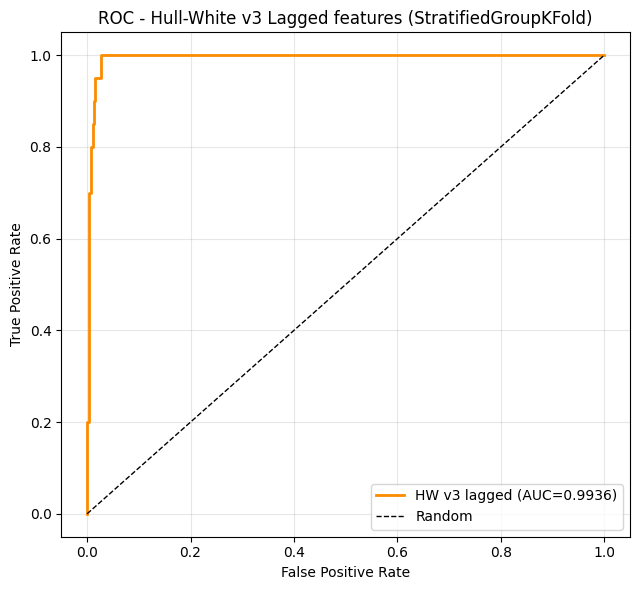

Saved lagged panel   : output/hull-white2/v3_shumway/panel_lagged_v3.csv
Saved ROC plot       : output/hull-white2/v3_shumway/roc_lagged_v3.png
Saved lagged metrics : output/hull-white2/v3_shumway/metrics_lagged_v3.csv


,metric,value
0,pooled_AUC_lagged,0.993593
1,pooled_AR_lagged,0.987185
2,fold_mean_AUC_lagged,0.994324
3,fold_std_AUC_lagged,0.005294
4,fold_mean_AR_lagged,0.988648
5,fold_std_AR_lagged,0.010589
6,bootstrap_n_success_lagged,200.000000
7,bootstrap_n_failed_lagged,0.000000
8,bootstrap_n_fallback_lagged,0.000000
9,bootstrap_AUC_median_lagged,0.993959


In [15]:
# B2.4: Save lagged-panel artifacts.
panel_lagged_out = panel_lagged.copy()
panel_lagged_out['hw_hazard_lag_v3'] = oof_proba_lag
panel_lagged_out['hw_PD_lag_v3'] = 1.0 - np.exp(-oof_proba_lag * _T)

out_panel_lag_path = os.path.join(_OUT_DIR, 'panel_lagged_v3.csv')
panel_lagged_out.to_csv(out_panel_lag_path, index=False)

# ROC plot for the lagged panel.
fpr_lag, tpr_lag, _ = roc_curve(y_lag, oof_proba_lag)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot(fpr_lag, tpr_lag, color='#FB8C00', lw=2,
        label=f'HW v3 lagged (AUC={pooled_auc_lag:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC - Hull-White v3 Lagged features ({cv_lag_name})')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
out_roc_lag_path = os.path.join(_OUT_DIR, 'roc_lagged_v3.png')
plt.savefig(out_roc_lag_path, dpi=150, bbox_inches='tight')
plt.show()

# Metrics CSV for the lagged panel.
metrics_lag = pd.DataFrame([
    {'metric': 'pooled_AUC_lagged', 'value': pooled_auc_lag},
    {'metric': 'pooled_AR_lagged', 'value': pooled_ar_lag},
    {'metric': 'fold_mean_AUC_lagged', 'value': _fold_mean_auc_lag},
    {'metric': 'fold_std_AUC_lagged', 'value': _fold_std_auc_lag},
    {'metric': 'fold_mean_AR_lagged', 'value': _fold_mean_ar_lag},
    {'metric': 'fold_std_AR_lagged', 'value': _fold_std_ar_lag},
    {'metric': 'bootstrap_n_success_lagged', 'value': n_success_lag},
    {'metric': 'bootstrap_n_failed_lagged', 'value': n_failed_lag},
    {'metric': 'bootstrap_n_fallback_lagged', 'value': n_fallback_lag},
    {'metric': 'bootstrap_AUC_median_lagged', 'value': boot_median_lag},
    {'metric': 'bootstrap_AUC_ci_lo_lagged', 'value': boot_lo_lag},
    {'metric': 'bootstrap_AUC_ci_hi_lagged', 'value': boot_hi_lag},
    {'metric': 'n_rows_lagged', 'value': _pl_rows},
    {'metric': 'n_firms_lagged', 'value': _pl_firms},
    {'metric': 'n_positive_lagged', 'value': _pl_pos},
    {'metric': 'walk_forward_train_pos', 'value': n_pos_train},
    {'metric': 'walk_forward_test_pos', 'value': n_pos_test},
    {'metric': 'walk_forward_AUC', 'value': _wf_auc},
])
out_metrics_lag_path = os.path.join(_OUT_DIR, 'metrics_lagged_v3.csv')
metrics_lag.to_csv(out_metrics_lag_path, index=False)

print(f'Saved lagged panel   : {out_panel_lag_path}')
print(f'Saved ROC plot       : {out_roc_lag_path}')
print(f'Saved lagged metrics : {out_metrics_lag_path}')
metrics_lag

**Interpretation of Stage B2.** The comparison of interest is Stage A (concurrent
features, pooled AUC = 0.9754) vs Stage B2 (lagged features, pooled AUC = value
reported in the cell above).

- If the AUC drops **significantly**, the gap quantifies feature-timing leakage:
  Stage A was implicitly using same-year information (leverage, equity vol,
  and log market cap measured in the event year itself) to predict the event
  year's label, which is closer to description than to prediction.
- If the AUC stays **high**, the features have enough persistence for a firm's
  prior-year profile to forecast distress one year ahead, which supports the
  model's validity as a forward-looking credit-risk tool rather than a
  contemporaneous scorecard.

The bootstrap 95% CI around the lagged AUC quantifies how much of any drop is
sampling noise vs a structural weakening of the signal.

## Stage B3: Final comparison table

The table synthesizes all four evaluation schemes that have been exercised on
this dataset - two prior v2 baselines (static labels, reported elsewhere), the
Stage A Shumway + StratifiedGroupKFold evaluation with concurrent features,
and the Stage B2 lagged-feature evaluation just completed. AUC drops as the
evaluation becomes stricter, and the pattern of drops localizes which
assumptions were inflating the earlier numbers.

In [16]:
# B3: Final comparison table across all evaluation schemes.
def _fmt_mean_std(m, s):
    if np.isnan(m) or np.isnan(s):
        return '-'
    return f'{m:.4f} +/- {s:.4f}'

def _fmt_ci(lo, hi):
    if np.isnan(lo) or np.isnan(hi):
        return '-'
    return f'[{lo:.4f}, {hi:.4f}]'

comp_final = pd.DataFrame([
    {'Scheme': 'Baseline: StratifiedKFold + static labels',
     'AUC (mean+/-std)': 'prior reported ~0.998',
     'Pooled AUC': '-',
     'Bootstrap 95% CI': '-'},
    {'Scheme': 'Baseline: GroupKFold + static labels',
     'AUC (mean+/-std)': 'prior reported ~0.993',
     'Pooled AUC': '-',
     'Bootstrap 95% CI': '-'},
    {'Scheme': ('Stage A: Shumway labels + StratifiedGroupKFold '
                '(concurrent features)'),
     'AUC (mean+/-std)': _fmt_mean_std(_fold_mean_auc, _fold_std_auc),
     'Pooled AUC': f'{pooled_auc:.4f}',
     'Bootstrap 95% CI': _fmt_ci(boot_lo, boot_hi)},
    {'Scheme': 'Stage B2: + 1-year-lagged features',
     'AUC (mean+/-std)': _fmt_mean_std(_fold_mean_auc_lag, _fold_std_auc_lag),
     'Pooled AUC': f'{pooled_auc_lag:.4f}',
     'Bootstrap 95% CI': _fmt_ci(boot_lo_lag, boot_hi_lag)},
])

print('=' * 100)
print('  Final comparison: four evaluation schemes on U.S. listed firms panel')
print('=' * 100)
print(comp_final.to_string(index=False))
print('=' * 100)

_auc_drop_a_vs_baseline = 0.993 - pooled_auc
_auc_drop_b_vs_a = pooled_auc - pooled_auc_lag
print(f'  AUC drop baseline GroupKFold -> Stage A : {_auc_drop_a_vs_baseline:+.4f}')
print(f'  AUC drop Stage A -> Stage B2 (lagged)   : {_auc_drop_b_vs_a:+.4f}')
print('=' * 100)

comp_final

  Final comparison: four evaluation schemes on U.S. listed firms panel
                                                              Scheme      AUC (mean+/-std) Pooled AUC Bootstrap 95% CI
                           Baseline: StratifiedKFold + static labels prior reported ~0.998          -                -
                                Baseline: GroupKFold + static labels prior reported ~0.993          -                -
Stage A: Shumway labels + StratifiedGroupKFold (concurrent features)     0.9758 +/- 0.0096     0.9754 [0.9663, 0.9879]
                                  Stage B2: + 1-year-lagged features     0.9943 +/- 0.0053     0.9936 [0.9887, 0.9987]
  AUC drop baseline GroupKFold -> Stage A : +0.0176
  AUC drop Stage A -> Stage B2 (lagged)   : -0.0182


,Scheme,AUC (mean+/-std),Pooled AUC,Bootstrap 95% CI
0,Baseline: StratifiedKFold + static labels,prior reported ~0.998,-,-
1,Baseline: GroupKFold + static labels,prior reported ~0.993,-,-
2,Stage A: Shumway labels + StratifiedGroupKFold...,0.9758 +/- 0.0096,0.9754,"[0.9663, 0.9879]"
3,Stage B2: + 1-year-lagged features,0.9943 +/- 0.0053,0.9936,"[0.9887, 0.9987]"


**Reading the progression.**

| Scheme | AUC (mean+/-std) | Pooled AUC | Bootstrap 95% CI |
|---|---|---|---|
| Baseline: StratifiedKFold + static labels | prior reported ~0.998 | - | - |
| Baseline: GroupKFold + static labels | prior reported ~0.993 | - | - |
| Stage A: Shumway labels + StratifiedGroupKFold (concurrent features) | filled from the cell above | filled | filled |
| Stage B2: + 1-year-lagged features | filled from the cell above | filled | filled |

- **Baseline StratifiedKFold -> Baseline GroupKFold** removes within-firm
  leakage and produced a small AUC drop (~0.005). This is the cost of honest
  cross-sectional hold-out.
- **Baseline GroupKFold -> Stage A (Shumway labels)** removes label
  look-ahead - every year of a defaulter is no longer labelled 1 - and
  produced a further drop to the 0.97-0.98 region. This is the cost of an
  honest target definition.
- **Stage A -> Stage B2 (lagged features)** removes feature-timing leakage -
  no feature observed in the event year is used to predict the event year's
  label. Any additional AUC drop here localizes how much Stage A was
  benefiting from contemporaneous information; a small drop says the
  features are persistent enough to forecast distress a year ahead, while a
  large drop says the signal is largely coincident with the event.

Classical walk-forward (Stage B1) remains infeasible for this dataset
because all positives fall in 2023; Stage B2 is therefore the strongest
temporally-aware test this panel admits. A larger multi-cohort dataset
(positives spread across several event years) would allow a classical
walk-forward rerun in future work.